Run any code cell from the `Question_1` directory using the `lab_entry_test` kernel. The preprocessed dataset and the model checkpoints in `checkpoints/` are included, so you can run the plotting and clustering cells directly. Saved figures are in `figures/`.

# (1)
Use online material to learn and get a general understanding of Variational Autoencoder (VAE). Briefly describe the forward step of VAE (about 3 sentences) and how to generate new samples (about 3 sentences). Briefly answer how to generate new samples similar to a specific input sample (about 3 sentences).



## Forward pass

1. Given input x, the encoder maps it onto a multivariate normal in the latent space. The multivariate normal is close to the standard multivariate normal (mean=0, var=1), but not exact (constrained by recovery loss and KL divergence)
2. The decoder samples from the latent mutivariate normal of x by taking $\mu + \epsilon\times\sigma$, $\epsilon$ is a noise sampled from standard normal
3. The decoder maps the latent back into  the high dimensional space, the mean is the reconstructed input, and used for computing loss

## Generating new samples

1. Draw a vector from the standard multivariate normal in the latent space
2. Decode that vector into distribution in the high dimensional space
3. Take the decoded mean to produce a new sample

## Generating samples similar to input

1. encode the input onto the latent space
2. sample from that encoded, latent space multivariate normal
3. decode

# (2)
Download a single-cell RNA-seq dataset here https://drive.google.com/file/d/1SO7PNJ8Ktz7v-Vaj1rFTNcfjZxvLKI-_/view?usp=sharing . This dataset is essentially an annotated matrix, where each row corresponds to a cell and each column corresponds to a gene. Each entry is the expression level of the gene in the specific cell. The matrix also has annotations, e.g. cell type labels. Read here https://anndata.readthedocs.io/en/latest/ about the h5ad file format, including the file structure, how to read h5ad file, check annotations, etc. How many cells, cell types, and genes are in this dataset?

In [1]:
from anndata.io import read_h5ad

adata = read_h5ad("cortex.h5ad")

print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Cell types:", adata.obs["label"].nunique())
print("Cell subtypes:", adata.obs["label2"].nunique())

Cells: 3005
Genes: 19972
Cell types: 7
Cell subtypes: 48


# (3)
Preprocess the data using the scanpy pipeline here https://scanpy-tutorials.readthedocs.io/en/latest/pbmc3k.html Please skip the “regress out” step. Please also don’t filter any cells. You may play with different parameters later and see which gives you the best downstream task performance.


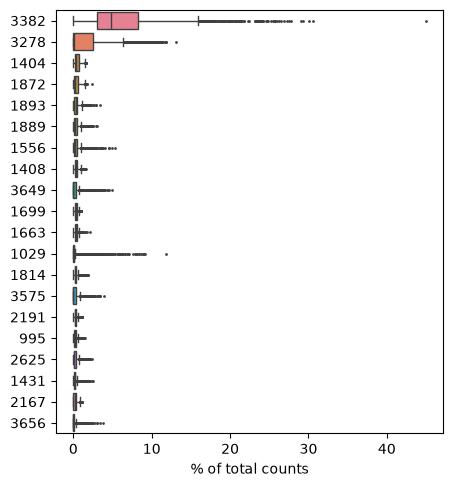

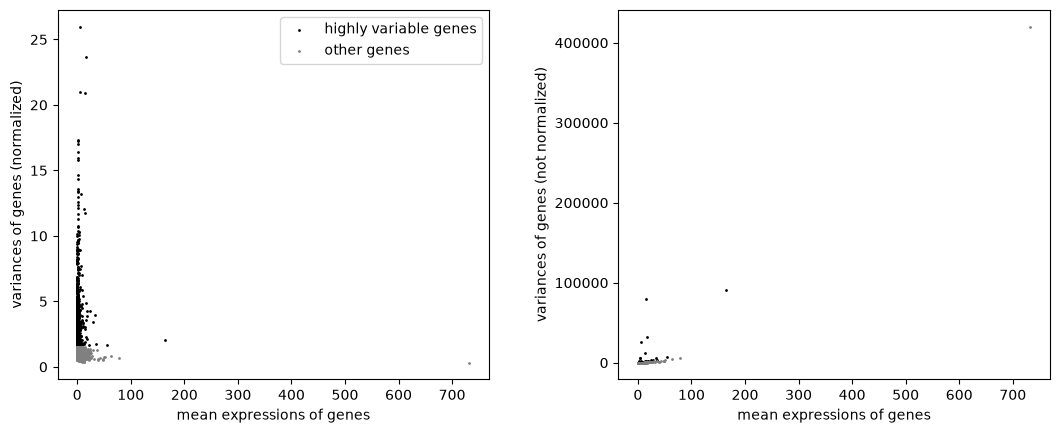

In [2]:
import scanpy as sc
from scanpy.io import read_h5ad

adata = read_h5ad("cortex.h5ad")
adata.var_names_make_unique()
adata.layers["counts"] = adata.X.copy()
sc.pl.highest_expr_genes(adata, n_top=20)

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", use="layers.counts")
sc.pl.highly_variable_genes(adata)
sc.pp.scale(adata, max_value=10, out="layers.scaled")

adata.write_h5ad("cortex_preprocessed.h5ad")

# (4)
Implement a VAE and train it on this cortex dataset. You can refer to any online material to implement the VAE. Extract the latent variable for each cell. Use the umap.UMAP() function in the package umap-learn to reduce the latent variable to 2D and make a scatter plot for all cells. The color of each dot (cell) should represent its ground truth cell type (can be found in the dataset). 

In [3]:
from scanpy.io import read_h5ad

from model import VAE, train_vae

adata = read_h5ad("cortex_preprocessed.h5ad")
train_vae(VAE, adata, "scaled", "checkpoints/cortex_vae.pt", epochs=30)

VAE | 30 epochs | final mean loss 6801.81


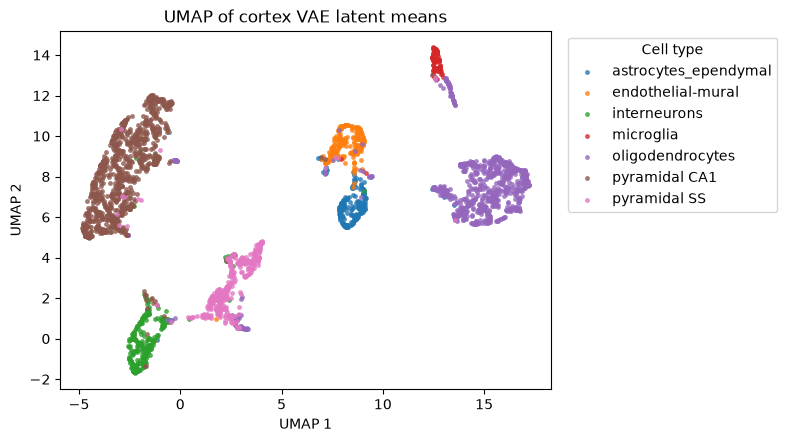

In [11]:
import matplotlib.pyplot as plt
import umap
from scanpy.io import read_h5ad

from model import RANDOM_SEED, VAE, load_latent_means

adata = read_h5ad("cortex_preprocessed.h5ad")
latent_means = load_latent_means(VAE, "checkpoints/cortex_vae.pt", adata.layers["scaled"])
cell_types = adata.obs["label"].astype("string").fillna("Unannotated")

embedding = umap.UMAP(
    n_components=2,
    n_neighbors=30,
    min_dist=0.1,
    metric="euclidean",
    random_state=RANDOM_SEED,
    n_jobs=1,
    compatibility_layout=True,
).fit_transform(latent_means)

figure, axis = plt.subplots(figsize=(8, 6))
for cell_type in sorted(cell_types.unique()):
    points = embedding[cell_types.eq(cell_type).to_numpy(dtype=bool)]
    axis.scatter(*points.T, label=cell_type, s=12, alpha=0.8, linewidths=0)
axis.set(xlabel="UMAP 1", ylabel="UMAP 2", title="UMAP of cortex VAE latent means", aspect="equal")
axis.legend(title="Cell type", loc="upper left", bbox_to_anchor=(1.02, 1))
figure.tight_layout()
figure.savefig("figures/cortex_vae_umap.png", dpi=300, bbox_inches="tight")
plt.show()

# (5)

Use Negative Binomial distribution to reconstruct the gene expression in the decoder of your VAE. Use data likelihood as your reconstruction loss. To do this, you need to use raw count data as your input (don’t use the logged values)

In [5]:
from scanpy.io import read_h5ad

from model import NBVAE, train_vae

adata = read_h5ad("cortex_preprocessed.h5ad")
train_vae(NBVAE, adata, "counts", "checkpoints/cortex_nb_vae.pt", epochs=30)

NBVAE | 30 epochs | final mean loss 11887.45


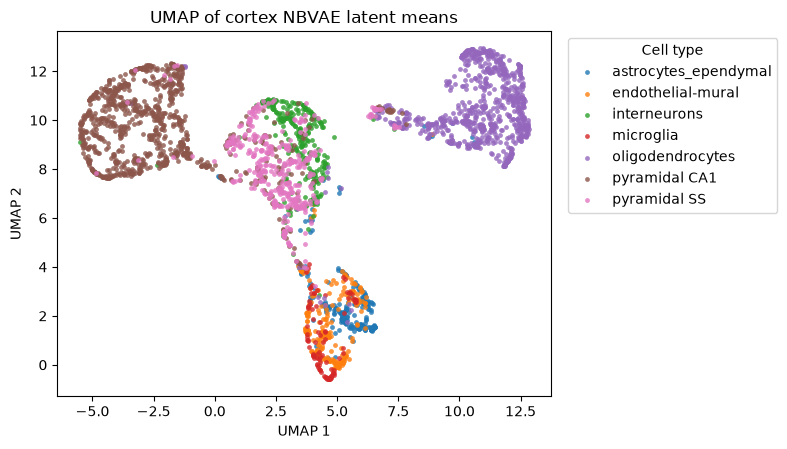

In [9]:
import matplotlib.pyplot as plt
import umap
from scanpy.io import read_h5ad

from model import RANDOM_SEED, NBVAE, load_latent_means

adata = read_h5ad("cortex_preprocessed.h5ad")
latent_means = load_latent_means(NBVAE, "checkpoints/cortex_nb_vae.pt", adata.layers["counts"])
cell_types = adata.obs["label"].astype("string").fillna("Unannotated")

embedding = umap.UMAP(
    n_components=2,
    n_neighbors=30,
    min_dist=0.1,
    metric="euclidean",
    random_state=RANDOM_SEED,
    n_jobs=1,
    compatibility_layout=True,
).fit_transform(latent_means)

figure, axis = plt.subplots(figsize=(8, 6))
for cell_type in sorted(cell_types.unique()):
    points = embedding[cell_types.eq(cell_type).to_numpy(dtype=bool)]
    axis.scatter(*points.T, label=cell_type, s=12, alpha=0.8, linewidths=0)
axis.set(xlabel="UMAP 1", ylabel="UMAP 2", title="UMAP of cortex NBVAE latent means", aspect="equal")
axis.legend(title="Cell type", loc="upper left", bbox_to_anchor=(1.02, 1))
figure.tight_layout()
figure.savefig("figures/cortex_nbvae_umap.png", dpi=300, bbox_inches="tight")
plt.show()

# (6)
Extract the latent variables (Z) for all cells. Run K-means clustering on the latent variables. Set K to be the same as the number of cell types. If the quality of the latent variables is good, then cells of the same cell type should have similar latent variables and should have the same K-means label. Compute ARI score (https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html) between the ground truth cell types and the labels given by K Means. A high ARI score means the labels are similar to the ground truth. What is your ARI score? Try to modify your VAE structure to improve the ARI score.

Adjusted Rand index: 0.8714


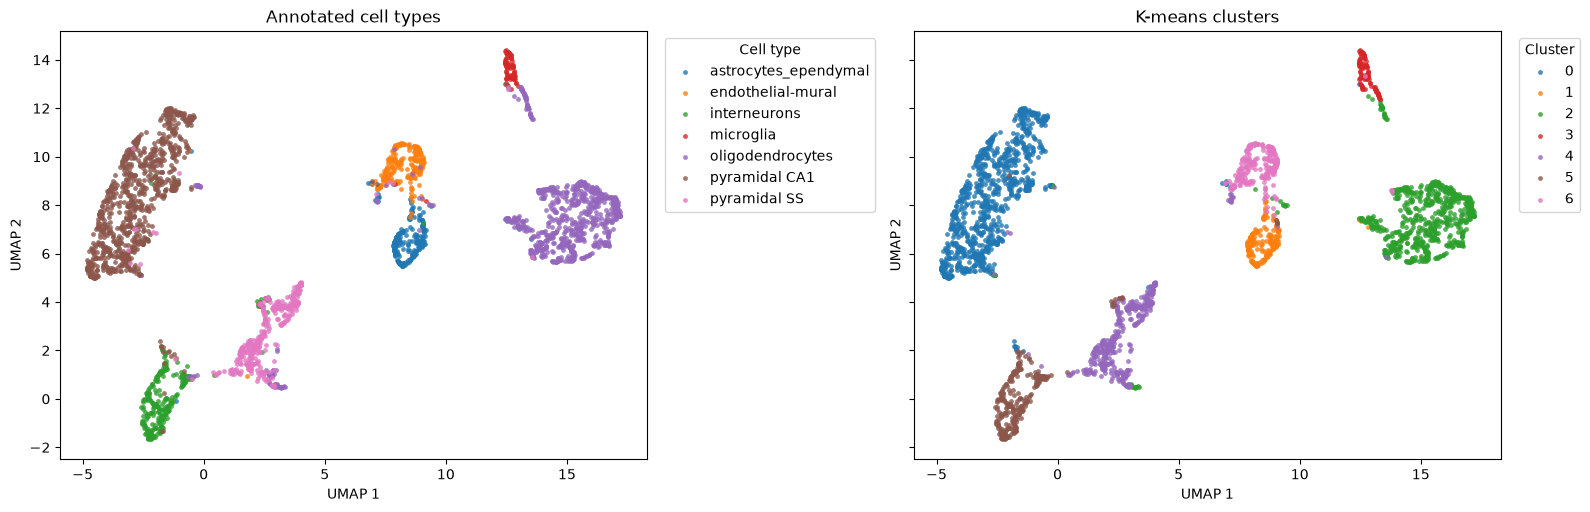

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import umap
from scanpy.io import read_h5ad
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

from model import RANDOM_SEED, VAE, load_latent_means

adata = read_h5ad("cortex_preprocessed.h5ad")
latent_means = load_latent_means(VAE, "checkpoints/cortex_vae.pt", adata.layers["scaled"])
cell_types = adata.obs["label"]
kmeans = KMeans(n_clusters=cell_types.nunique(), init="random", n_init=1, random_state=RANDOM_SEED)
clusters = kmeans.fit_predict(latent_means)
print(f"Adjusted Rand index: {adjusted_rand_score(cell_types, clusters):.4f}")

embedding = umap.UMAP(
    n_components=2,
    n_neighbors=30,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
    n_jobs=1,
    compatibility_layout=True,
).fit_transform(latent_means)

figure, (truth_axis, cluster_axis) = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
for axis, labels, title, legend_title in (
    (truth_axis, cell_types.to_numpy(), "Annotated cell types", "Cell type"),
    (cluster_axis, clusters, "K-means clusters", "Cluster"),
):
    for label in np.unique(labels):
        points = embedding[labels == label]
        axis.scatter(*points.T, label=str(label), s=12, alpha=0.8, linewidths=0)
    axis.set(xlabel="UMAP 1", ylabel="UMAP 2", title=title, aspect="equal")
    axis.legend(title=legend_title, loc="upper left", bbox_to_anchor=(1.02, 1))
figure.tight_layout()
plt.show()

# (7)
Find highly variable genes. Give them more weights when computing the reconstruction loss and train your VAE again. Can you get a higher ARI score this time?

In [2]:
import numpy as np
import pandas as pd
import torch
from scanpy.io import read_h5ad
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

from model import VAE, train_vae

adata = read_h5ad("cortex_preprocessed.h5ad")
highly_variable = adata.var["highly_variable"].to_numpy(dtype=bool)
gene_weights = np.where(highly_variable, 3.0, 1.0)
gene_weights /= gene_weights.mean()

weighted_checkpoint = "checkpoints/cortex_vae_hvg.pt"
train_vae(VAE, adata, "scaled", weighted_checkpoint, epochs=30, gene_weights=gene_weights)

cell_types = adata.obs["label"]
scaled_expression = torch.as_tensor(adata.layers["scaled"], dtype=torch.float32)
hvg_weights = torch.as_tensor(gene_weights, dtype=scaled_expression.dtype)


@torch.inference_mode()
def evaluate_checkpoint(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model = VAE(**checkpoint["model_config"])
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    latent_batches = []
    uniform_loss_sum = 0.0
    hvg_loss_sum = 0.0
    for expression in scaled_expression.split(128):
        latent_means, _ = model.encode(expression)
        latent_batches.append(latent_means)
        reconstructed = model.decoder(latent_means)
        uniform_loss_sum += model.reconstruction_loss(reconstructed, expression).sum(dtype=torch.float64).item()
        hvg_loss_sum += model.reconstruction_loss(reconstructed, expression, hvg_weights).sum(dtype=torch.float64).item()

    kmeans = KMeans(n_clusters=cell_types.nunique(), init="random", n_init=1, random_state=42)
    clusters = kmeans.fit_predict(torch.cat(latent_batches).numpy())
    return {
        "ARI": adjusted_rand_score(cell_types, clusters),
        "Reconstruction loss per cell (uniform)": uniform_loss_sum / len(scaled_expression),
        "Reconstruction loss per cell (HVG-weighted)": hvg_loss_sum / len(scaled_expression),
    }


results = pd.DataFrame(
    [evaluate_checkpoint("checkpoints/cortex_vae.pt"), evaluate_checkpoint(weighted_checkpoint)],
    index=["Base VAE", "HVG-weighted VAE"],
)
display(results.round(4))
ari_change = results["ARI"].diff().at["HVG-weighted VAE"]
print(f"ARI change: {ari_change:+.4f}")

VAE | 30 epochs | final mean loss 6652.23


,ARI,Reconstruction loss per cell (uniform),Reconstruction loss per cell (HVG-weighted)
Base VAE,0.8714,6771.6465,6661.2307
HVG-weighted VAE,0.8689,6761.1374,6618.7262


ARI change: -0.0025


I expected that giving HVGs more weight would improve the performance because I assumed that HVGs are the variable and indicator genes across different cell types. The reconstruction loss improved very slightly, while the latent space representation didn't improve given the downstream kmeans clustering.

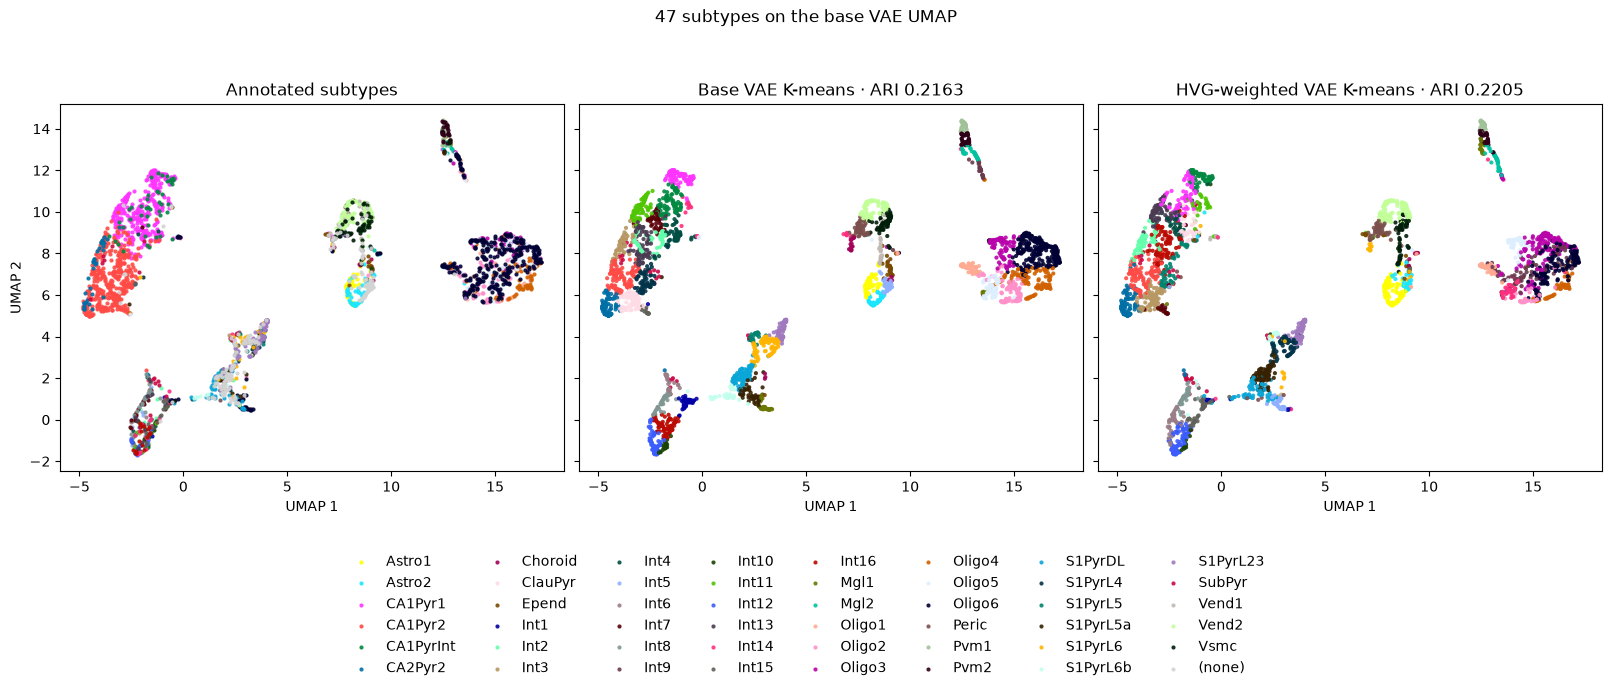

In [2]:
import matplotlib.pyplot as plt
import scanpy as sc
import umap
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, confusion_matrix

from model import RANDOM_SEED, VAE, load_latent_means

adata = sc.io.read_h5ad("cortex_preprocessed.h5ad")
subtypes = adata.obs["label2"].fillna("(none)")
annotated = subtypes != "(none)"
known_subtypes = subtypes[annotated].cat.remove_unused_categories()
subtype_names = known_subtypes.cat.categories
n_clusters = len(subtype_names)

expression = adata.layers["scaled"]
base_latent = load_latent_means(VAE, "checkpoints/cortex_vae.pt", expression)
weighted_latent = load_latent_means(VAE, "checkpoints/cortex_vae_hvg.pt", expression)
kmeans = KMeans(n_clusters=n_clusters, init="random", n_init=1, random_state=RANDOM_SEED)
base_clusters = kmeans.fit_predict(base_latent)
weighted_clusters = kmeans.fit_predict(weighted_latent)
embedding = umap.UMAP(
    n_neighbors=30, min_dist=0.1, random_state=RANDOM_SEED, n_jobs=1, compatibility_layout=True,
).fit_transform(base_latent)

figure, axes = plt.subplots(1, 3, figsize=(16, 6.8), sharex=True, sharey=True, layout="constrained")
point_style = dict(s=9, alpha=0.9, linewidths=0)
subtype_colors = dict(zip(subtype_names, sc.pl.palettes.default_102))
subtype_colors["(none)"] = "lightgray"
for subtype, color in subtype_colors.items():
    points = embedding[subtypes == subtype]
    axes[0].scatter(*points.T, color=color, label=subtype, **point_style)
axes[0].set(title="Annotated subtypes", ylabel="UMAP 2")

for axis, title, clusters in zip(axes[1:], ["Base VAE", "HVG-weighted VAE"], [base_clusters, weighted_clusters]):
    known_clusters = clusters[annotated]
    ari = adjusted_rand_score(known_subtypes, known_clusters)
    overlap = confusion_matrix(known_subtypes.cat.codes, known_clusters, labels=range(n_clusters))
    subtype_ids, cluster_ids = linear_sum_assignment(overlap, maximize=True)
    cluster_colors = dict(zip(cluster_ids, subtype_names[subtype_ids].map(subtype_colors)))
    axis.scatter(*embedding.T, c=[cluster_colors[i] for i in clusters], **point_style)
    axis.set_title(f"{title} K-means · ARI {ari:.4f}")

for axis in axes:
    axis.set(xlabel="UMAP 1", aspect="equal")
figure.suptitle(f"{n_clusters} subtypes on the base VAE UMAP")
figure.legend(loc="outside lower center", ncols=8, frameon=False)
plt.show()

Direct kmeans clustering performance on the subtypes also showed little difference between weighting HVGs and the base VAE. I think the main cause is that the Kmeans clustering is rough and unsupervised, it does not know which of the dimensions in the latent are relevant for typing and which are relevant for certain genetic circuits (as learning this improves reconstruction). So different cell types that display the same genetic circuits will have closer distance than expected and vice versa

# (8)
*** Explore any other methods to improve the ARI score.

The first thing to do would be to probe the latent with a supervised neuralnet, instead of using them for kmeans directly


In [3]:
from copy import deepcopy

from scanpy.io import read_h5ad
from sklearn.metrics import accuracy_score, adjusted_rand_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

from model import RANDOM_SEED, VAE, load_latent_means

adata = read_h5ad("cortex_preprocessed.h5ad")
subtypes = adata.obs["label2"]
annotated = (subtypes.notna() & subtypes.ne("(none)")).to_numpy()
labels = subtypes[annotated].to_numpy()
latent = load_latent_means(VAE, "checkpoints/cortex_vae.pt", adata.layers["scaled"][annotated])

train_latent, test_latent, train_labels, test_labels = train_test_split(
    latent, labels, test_size=0.20, stratify=labels, random_state=RANDOM_SEED,
)
train_latent, val_latent, train_labels, val_labels = train_test_split(
    train_latent, train_labels, test_size=0.25, stratify=train_labels, random_state=RANDOM_SEED,
)

scaler = StandardScaler().fit(train_latent)
train_latent = scaler.transform(train_latent)
val_latent = scaler.transform(val_latent)

classifier = MLPClassifier(hidden_layer_sizes=(32,), activation="relu", random_state=RANDOM_SEED)
classes = sorted(set(train_labels))
best_val_loss = float("inf")
for epoch in range(1, 201):
    classifier.partial_fit(train_latent, train_labels, classes=classes)
    val_loss = log_loss(val_labels, classifier.predict_proba(val_latent), labels=classes)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_classifier = deepcopy(classifier)

test_predictions = best_classifier.predict(scaler.transform(test_latent))
print(f"Cells: {len(train_labels)} train, {len(val_labels)} validation, {len(test_labels)} test")
print(f"Best validation log loss: {best_val_loss:.4f} at epoch {best_epoch}")
print(f"Test accuracy: {accuracy_score(test_labels, test_predictions):.4f}")
print(f"Test ARI: {adjusted_rand_score(test_labels, test_predictions):.4f}")

Cells: 1689 train, 563 validation, 564 test
Best validation log loss: 1.2466 at epoch 200
Test accuracy: 0.5780
Test ARI: 0.5409


More directly, we can include the labels (type and subtype) in the input for the VAE, train on it, and make the prediction. Because this is discrete, the decoder will generate logits for each type, and the reconstruction loss for this would be categorical cross entropy

Each row supplies gene expression and two targets, `label` (type) and `label2` (subtype). The encoder reads expression alone. The four-dimensional latent feeds the decoder’s 256-unit ReLU hidden layer. Three output heads use those same activations to reconstruct expression and predict type and subtype. label loss is categorical cross entropy

In [1]:
from copy import deepcopy

import torch
from scanpy.io import read_h5ad
from sklearn.metrics import accuracy_score, adjusted_rand_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset

from model import RANDOM_SEED, CellLabelVAE

adata = read_h5ad("cortex_preprocessed.h5ad")
subtypes = adata.obs["label2"]
annotated = subtypes.notna() & subtypes.ne("(none)")
labels = adata.obs.loc[annotated, ["label", "label2"]]
type_ids, type_names = labels["label"].factorize(sort=True)
subtype_ids, subtype_names = labels["label2"].factorize(sort=True)

train_rows, test_rows = train_test_split(
    range(len(labels)), test_size=0.20, stratify=labels["label2"], random_state=RANDOM_SEED,
)
train_rows, val_rows = train_test_split(
    train_rows, test_size=0.25, stratify=labels["label2"].iloc[train_rows], random_state=RANDOM_SEED,
)

expression = adata.X[annotated.to_numpy()]
scaler = StandardScaler().fit(expression[train_rows])
expression = torch.as_tensor(scaler.transform(expression).clip(-10, 10), dtype=torch.float32)
type_targets = torch.as_tensor(type_ids, dtype=torch.long)
subtype_targets = torch.as_tensor(subtype_ids, dtype=torch.long)
dataset = TensorDataset(expression, type_targets, subtype_targets)
torch.manual_seed(RANDOM_SEED)
shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(Subset(dataset, train_rows), batch_size=128, shuffle=True, generator=shuffle_generator)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CellLabelVAE(expression.shape[1], len(type_names), len(subtype_names), latent_dim=4).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
label_loss_weight = 100.0


@torch.inference_mode()
def predict_logits(rows):
    model.eval()
    latent_means, _ = model.encode(expression[rows].to(device))
    return model.label_logits(latent_means)


best_val_loss = float("inf")
for epoch in range(1, 51):
    model.train()
    for genes, cell_types, cell_subtypes in train_loader:
        genes = genes.to(device)
        optimizer.zero_grad()
        (reconstruction, type_logits, subtype_logits), mean, log_variance = model(genes)
        expression_loss = model.reconstruction_loss(reconstruction, genes).mean()
        kl_loss = 0.5 * (mean.square() + log_variance.exp() - 1 - log_variance).sum(dim=1).mean()
        type_loss = F.cross_entropy(type_logits, cell_types.to(device))
        subtype_loss = F.cross_entropy(subtype_logits, cell_subtypes.to(device))
        loss = expression_loss + kl_loss + label_loss_weight * (type_loss + subtype_loss)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0, error_if_nonfinite=True)
        optimizer.step()

    _, val_subtype_logits = predict_logits(val_rows)
    val_loss = F.cross_entropy(val_subtype_logits, subtype_targets[val_rows].to(device)).item()
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_weights = deepcopy(model.state_dict())

model.load_state_dict(best_weights)
test_type_logits, test_subtype_logits = predict_logits(test_rows)
print(f"Cells: {len(train_rows)} train, {len(val_rows)} validation, {len(test_rows)} test")
print(f"Best validation subtype loss: {best_val_loss:.4f} at epoch {best_epoch}")
for name, targets, logits in (
    ("Type", type_targets, test_type_logits),
    ("Subtype", subtype_targets, test_subtype_logits),
):
    truth = targets[test_rows].numpy()
    predicted = logits.argmax(dim=1).cpu().numpy()
    print(f"{name} test accuracy: {accuracy_score(truth, predicted):.4f} | ARI: {adjusted_rand_score(truth, predicted):.4f}")

Cells: 1689 train, 563 validation, 564 test
Best validation subtype loss: 1.1458 at epoch 47
Type test accuracy: 0.9557 | ARI: 0.9113
Subtype test accuracy: 0.6170 | ARI: 0.5818


This approach is moderately better than the probe approach. Taking into account that the probe is a mlp with 32 hidden size, and that the typing heads (type and subtype) are single 256->#types layers, the two approaches demonstrated similar capacity.